# Laboratorium 2 — Trenowanie i strojenie klasyfikatora obrazów

**Cel:** wziąć baseline z Lab 1 i poprawić jego generalizację — augmentacją, BatchNorm i dropout, weight decay oraz harmonogramem współczynnika uczenia. Porównamy krzywe uczenia i przerwę train–test.

*Prowadzący: dr Tomasz Cieplak / mgr inż. Patryk Marek, Rok akademicki: 2026/27*

## 0. Instalacja zależności

In [1]:
!pip install torch torchvision matplotlib

## Import bibliotek i wybór urządzenia

W Colab: **Runtime → Change runtime type → GPU**.

In [2]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.11.0+cu130 | urządzenie: cuda


## 1. Dane: FashionMNIST z augmentacją i bez

Ten sam zbiór wczytamy w dwóch wariantach transformacji treningowej: **czysty** (baseline) i **z augmentacją** (losowe odbicie + wycinek z paddingiem). Augmentację stosujemy **tylko** na treningu; test zawsze bez augmentacji.

In [3]:
mean, std = 0.2860, 0.3530

test_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,)),
])
train_tf_plain = test_tf
train_tf_aug = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(28, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,)),
])

train_plain = torchvision.datasets.FashionMNIST("./data", train=True,  download=True, transform=train_tf_plain)
train_aug   = torchvision.datasets.FashionMNIST("./data", train=True,  download=True, transform=train_tf_aug)
test_ds     = torchvision.datasets.FashionMNIST("./data", train=False, download=True, transform=test_tf)
classes = test_ds.classes

def loaders(train_ds, bs=128):
    return (DataLoader(train_ds, batch_size=bs, shuffle=True),
            DataLoader(test_ds,  batch_size=256, shuffle=False))
print("Trening:", len(train_plain), "| Test:", len(test_ds))

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 172kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.21MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 10.8MB/s]

Trening: 60000 | Test: 10000


## 2. Konfigurowalny model (BatchNorm, Dropout)

Ten sam szkielet MLP z przełącznikami: `use_bn` włącza normalizację wsadową, `p_drop` — dropout. Pozwala to porównywać warianty regularyzacji bez pisania nowej klasy.

In [4]:
class MLP(nn.Module):
    def __init__(self, in_dim=28*28, hidden=(256, 128), n_classes=10,
                 use_bn=False, p_drop=0.0):
        super().__init__()
        layers, d = [nn.Flatten()], in_dim
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if use_bn:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if p_drop > 0:
                layers.append(nn.Dropout(p_drop))
            d = h
        layers.append(nn.Linear(d, n_classes))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

print(MLP(use_bn=True, p_drop=0.3))

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): ReLU()
    (4): Dropout(p=0.3, inplace=False)
    (5): Linear(in_features=256, out_features=128, bias=True)
    (6): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU()
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=128, out_features=10, bias=True)
  )
)


## 3. Reużywalna funkcja treningu

Jedna funkcja obsługuje wybór optymalizatora, **weight decay** oraz **scheduler** (StepLR). Zwraca historię strat i accuracy — użyjemy jej do wszystkich eksperymentów.

In [5]:
def evaluate(model, dl):
    model.eval()
    correct = total = 0
    loss_sum = 0.0
    crit = nn.CrossEntropyLoss(reduction="sum")
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += crit(out, yb).item()
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.numel()
    return loss_sum/total, correct/total

def run_training(model, train_dl, test_dl, epochs=10, lr=1e-3,
                 weight_decay=0.0, optimizer="adam", use_scheduler=False, verbose=True):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    if optimizer == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=max(1, epochs//3), gamma=0.5) if use_scheduler else None
    hist = {"train_loss": [], "test_loss": [], "test_acc": []}
    n = len(train_dl.dataset)
    for epoch in range(1, epochs+1):
        model.train()
        run = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            opt.step()
            run += loss.item()*yb.numel()
        if sched: sched.step()
        tr = run/n
        te, acc = evaluate(model, test_dl)
        hist["train_loss"].append(tr); hist["test_loss"].append(te); hist["test_acc"].append(acc)
        if verbose:
            print(f"Epoka {epoch:2d} | trening {tr:.3f} | test {te:.3f} | accuracy {acc*100:.2f}%")
    return hist

## 4. Eksperyment: baseline vs strojony

**Baseline** — jak w Lab 1: bez regularyzacji, dane czyste, Adam. **Strojony** — augmentacja + BatchNorm + dropout + weight decay + scheduler. Oba po tyle samo epok.

In [6]:
EPOCHS = 12

print("== BASELINE ==")
tr_dl, te_dl = loaders(train_plain)
base = MLP(use_bn=False, p_drop=0.0)
hist_base = run_training(base, tr_dl, te_dl, epochs=EPOCHS, lr=1e-3, weight_decay=0.0, use_scheduler=False)

print("\n== STROJONY ==")
tr_dl_a, te_dl = loaders(train_aug)
tuned = MLP(use_bn=True, p_drop=0.3)
hist_tuned = run_training(tuned, tr_dl_a, te_dl, epochs=EPOCHS, lr=1e-3, weight_decay=1e-4, use_scheduler=True)

print(f"\nNajlepsze accuracy — baseline: {max(hist_base['test_acc'])*100:.2f}% | strojony: {max(hist_tuned['test_acc'])*100:.2f}%")

== BASELINE ==
Epoka  1 | trening 0.485 | test 0.416 | accuracy 84.69%
Epoka  2 | trening 0.349 | test 0.364 | accuracy 86.80%
Epoka  3 | trening 0.312 | test 0.354 | accuracy 86.97%
Epoka  4 | trening 0.287 | test 0.347 | accuracy 87.62%
Epoka  5 | trening 0.264 | test 0.326 | accuracy 88.27%
Epoka  6 | trening 0.251 | test 0.344 | accuracy 87.74%
Epoka  7 | trening 0.235 | test 0.337 | accuracy 88.04%
Epoka  8 | trening 0.223 | test 0.325 | accuracy 88.69%
Epoka  9 | trening 0.212 | test 0.321 | accuracy 89.11%
Epoka 10 | trening 0.198 | test 0.342 | accuracy 88.46%
Epoka 11 | trening 0.191 | test 0.338 | accuracy 88.96%
Epoka 12 | trening 0.181 | test 0.351 | accuracy 88.88%

== STROJONY ==
Epoka  1 | trening 0.942 | test 0.667 | accuracy 74.26%
Epoka  2 | trening 0.752 | test 0.614 | accuracy 76.69%
Epoka  3 | trening 0.707 | test 0.595 | accuracy 77.17%
Epoka  4 | trening 0.680 | test 0.557 | accuracy 78.94%
Epoka  5 | trening 0.643 | test 0.538 | accuracy 79.60%
Epoka  6 | trenin

## 5. Porównanie krzywych i przerwa train–test

Regularyzacja i augmentacja zwykle zmniejszają **przerwę** między stratą treningową a testową (mniej przeuczenia), często przy wyższej accuracy testowej.

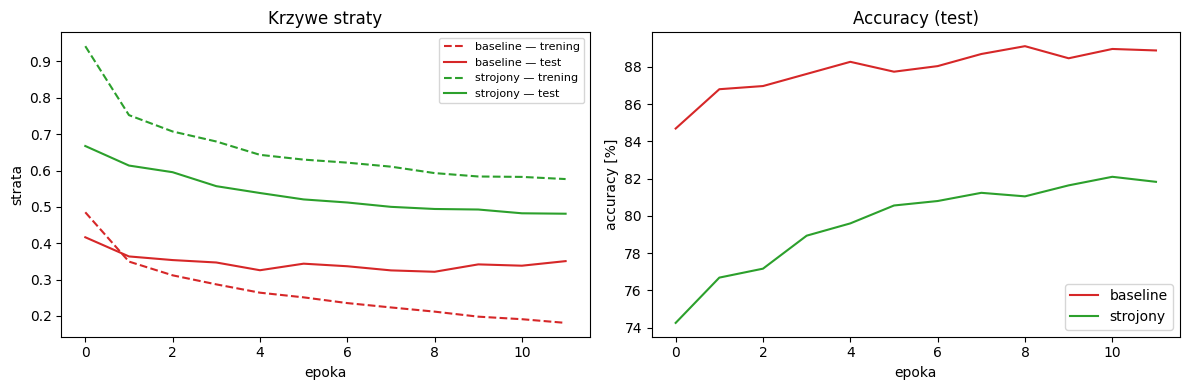

baseline  | przerwa test-trening (strata): 0.170 | accuracy: 88.88%
strojony  | przerwa test-trening (strata): -0.095 | accuracy: 81.83%


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for name, h, c in [("baseline", hist_base, "tab:red"), ("strojony", hist_tuned, "tab:green")]:
    ax1.plot(h["train_loss"], "--", color=c, label=f"{name} — trening")
    ax1.plot(h["test_loss"],  "-",  color=c, label=f"{name} — test")
    ax2.plot([a*100 for a in h["test_acc"]], color=c, label=name)
ax1.set_xlabel("epoka"); ax1.set_ylabel("strata"); ax1.legend(fontsize=8); ax1.set_title("Krzywe straty")
ax2.set_xlabel("epoka"); ax2.set_ylabel("accuracy [%]"); ax2.legend(); ax2.set_title("Accuracy (test)")
plt.tight_layout(); plt.show()

for name, h in [("baseline", hist_base), ("strojony", hist_tuned)]:
    gap = h["test_loss"][-1] - h["train_loss"][-1]
    print(f"{name:9s} | przerwa test-trening (strata): {gap:.3f} | accuracy: {h['test_acc'][-1]*100:.2f}%")

## 6. (opcjonalnie) Wpływ współczynnika uczenia

Krótki przegląd: ten sam model uczony kilka epok przy różnych wartościach LR. Zbyt duży LR rozbija trening, zbyt mały uczy wolno.

lr=0.1     -> accuracy 24.06%
lr=0.01    -> accuracy 85.09%
lr=0.001   -> accuracy 87.81%
lr=0.0001  -> accuracy 85.28%


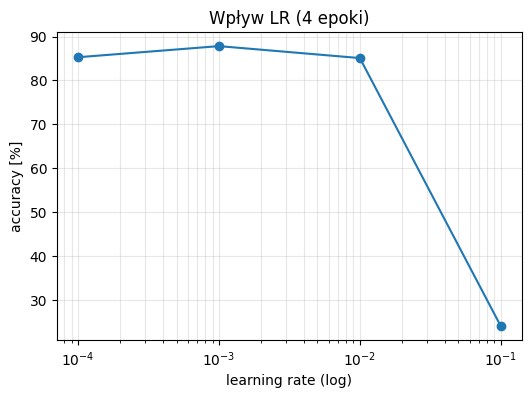

In [8]:
lrs = [1e-1, 1e-2, 1e-3, 1e-4]
acc_by_lr = []
tr_dl, te_dl = loaders(train_plain)
for lr in lrs:
    m = MLP(use_bn=False, p_drop=0.0)
    h = run_training(m, tr_dl, te_dl, epochs=4, lr=lr, use_scheduler=False, verbose=False)
    acc_by_lr.append(max(h["test_acc"]))
    print(f"lr={lr:<7} -> accuracy {max(h['test_acc'])*100:.2f}%")

plt.figure(figsize=(6,4))
plt.semilogx(lrs, [a*100 for a in acc_by_lr], "o-")
plt.xlabel("learning rate (log)"); plt.ylabel("accuracy [%]"); plt.title("Wpływ LR (4 epoki)")
plt.grid(True, which="both", alpha=0.3); plt.show()

## 7. Podsumowanie

- Przeuczenie rozpoznajemy po rosnącej przerwie train–test; celem jest generalizacja.
- Najskuteczniejsze dźwignie: **augmentacja**, **BatchNorm/dropout**, **weight decay**, **scheduler LR**.
- Współczynnik uczenia to najważniejszy hiperparametr — warto go dobrać jako pierwszy.
- Te same techniki wracają przy głębszych sieciach i CNN (zajęcia 4).

**Zadanie na sprawozdanie:** zobacz `zadanie.md`.

---
*Prowadzący: dr Tomasz Cieplak / mgr inż. Patryk Marek, Rok akademicki: 2026/27*